In [8]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder

In [9]:
data = pd.read_csv('Churn_Modelling.csv')
data

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [10]:
data.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [11]:
print(data.isnull().sum())


RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [12]:
data.iloc[:,3:]

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [13]:
data.drop(columns=data.iloc[:, :3].columns, inplace=True)


C:\Users\karth\AppData\Local\Temp\ipykernel_9880\1210707244.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(columns=data.iloc[:, :3].columns, inplace=True)


In [14]:
data['NumOfProducts'].value_counts()

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

In [15]:
data

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [16]:
categorical = [i for i in data.columns if data[i].dtype == 'O']
numerical = [i for i in data.columns if data[i].dtype != 'O']

In [17]:
print(categorical)
numerical

[]


['CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

In [18]:
le = LabelEncoder()
ohe = OneHotEncoder()

data['Gender'] = le.fit_transform(data['Gender'])

In [19]:
ohe_geo = ohe.fit_transform(data[['Geography']]).toarray()
ohe_geo
geo_encoded_df = pd.DataFrame(ohe_geo, columns= ohe.get_feature_names_out())

In [20]:
data = pd.concat([data.drop(columns='Geography'),geo_encoded_df],axis = 1)

In [21]:
data.columns

Index(['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
       'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited',
       'Geography_France', 'Geography_Germany', 'Geography_Spain'],
      dtype='str')

In [22]:
data = data[['CreditScore', 'Gender', 'Age','Geography_France', 'Geography_Germany', 'Geography_Spain', 'Tenure', 'Balance', 'NumOfProducts',
       'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']]

In [23]:
data

,CreditScore,Gender,Age,Geography_France,Geography_Germany,Geography_Spain,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,0,42,1.0,0.0,0.0,2,0.00,1,1,1,101348.88,1
1,608,0,41,0.0,0.0,1.0,1,83807.86,1,0,1,112542.58,0
2,502,0,42,1.0,0.0,0.0,8,159660.80,3,1,0,113931.57,1
3,699,0,39,1.0,0.0,0.0,1,0.00,2,0,0,93826.63,0
4,850,0,43,0.0,0.0,1.0,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,1,39,1.0,0.0,0.0,5,0.00,2,1,0,96270.64,0
9996,516,1,35,1.0,0.0,0.0,10,57369.61,1,1,1,101699.77,0
9997,709,0,36,1.0,0.0,0.0,7,0.00,1,0,1,42085.58,1
9998,772,1,42,0.0,1.0,0.0,3,75075.31,2,1,0,92888.52,1


In [24]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CreditScore        10000 non-null  int64  
 1   Gender             10000 non-null  int64  
 2   Age                10000 non-null  int64  
 3   Geography_France   10000 non-null  float64
 4   Geography_Germany  10000 non-null  float64
 5   Geography_Spain    10000 non-null  float64
 6   Tenure             10000 non-null  int64  
 7   Balance            10000 non-null  float64
 8   NumOfProducts      10000 non-null  int64  
 9   HasCrCard          10000 non-null  int64  
 10  IsActiveMember     10000 non-null  int64  
 11  EstimatedSalary    10000 non-null  float64
 12  Exited             10000 non-null  int64  
dtypes: float64(5), int64(8)
memory usage: 1015.8 KB


In [25]:
data.describe()

,CreditScore,Gender,Age,Geography_France,Geography_Germany,Geography_Spain,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,0.545700,38.921800,0.501400,0.250900,0.247700,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,0.497932,10.487806,0.500023,0.433553,0.431698,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,0.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,0.000000,32.000000,0.000000,0.000000,0.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,1.000000,37.000000,1.000000,0.000000,0.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,1.000000,44.000000,1.000000,1.000000,0.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,1.000000,92.000000,1.000000,1.000000,1.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


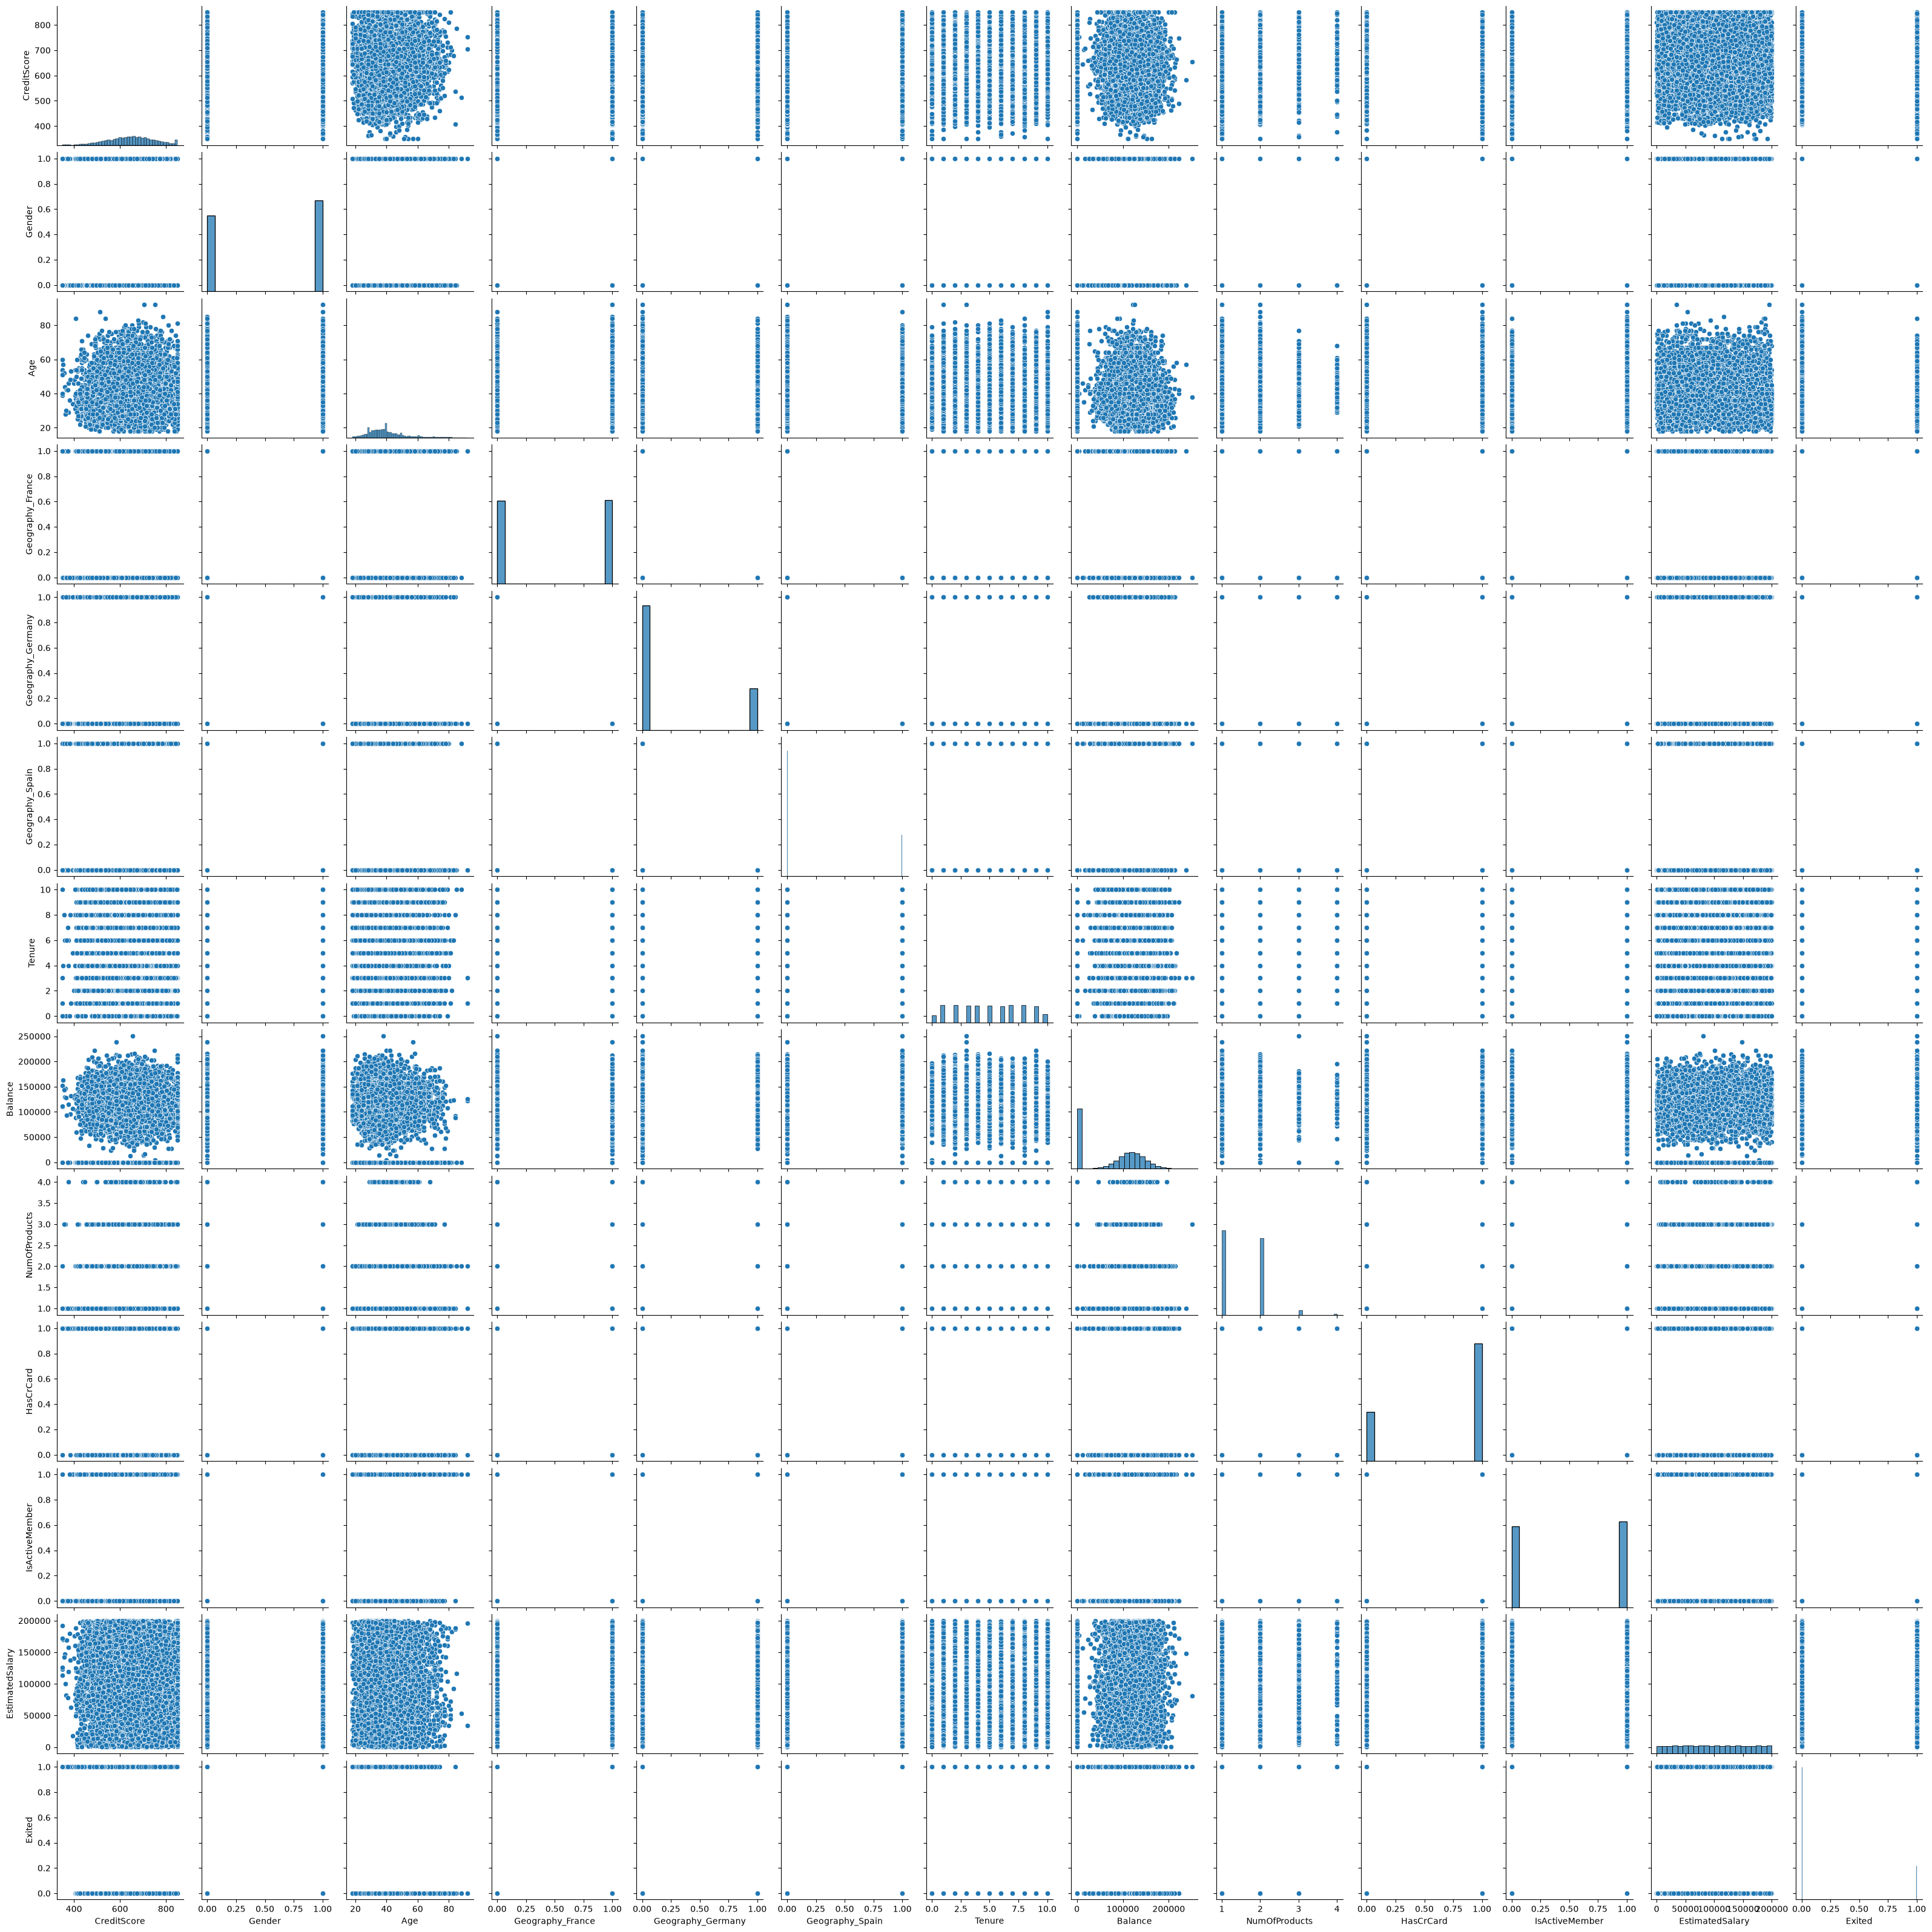

In [26]:
import seaborn as sns
sns.pairplot(data)

In [27]:
X = data.drop(columns=data.iloc[:, -1:])
Y = data.iloc[:, -1]
X.head()


,CreditScore,Gender,Age,Geography_France,Geography_Germany,Geography_Spain,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,0,42,1.0,0.0,0.0,2,0.00,1,1,1,101348.88
1,608,0,41,0.0,0.0,1.0,1,83807.86,1,0,1,112542.58
2,502,0,42,1.0,0.0,0.0,8,159660.80,3,1,0,113931.57
3,699,0,39,1.0,0.0,0.0,1,0.00,2,0,0,93826.63
4,850,0,43,0.0,0.0,1.0,2,125510.82,1,1,1,79084.10


In [28]:
Y.head()

0    1
1    0
2    1
3    0
4    0
Name: Exited, dtype: int64

In [29]:
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [30]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [31]:
import pickle

with open ('scaler.pkl','wb') as file:
    pickle.dump(scaler,file)

with open ('ohe.pkl','wb') as file:
    pickle.dump(ohe,file)

with open ('lencoder.pkl','wb') as file:
    pickle.dump(le,file)

In [32]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

In [33]:
model = Sequential([
    Dense(64,activation='relu',input_shape = (X_train.shape[1],)),
    Dense(32, activation = 'relu'),
    Dense(1,activation = 'sigmoid')
])

c:\Users\karth\NLP Pract\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [34]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
model.compile(optimizer='Adam', loss = 'binary_crossentropy', metrics=['accuracy'])

In [36]:
early_callback = EarlyStopping(monitor='val_loss', patience=5,restore_best_weights=True)

In [37]:
history = model.fit(X_train,Y_train, validation_data=(X_test,Y_test), callbacks= [early_callback],epochs=100,batch_size=100)

Epoch 1/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8023 - loss: 0.4661 - val_accuracy: 0.8235 - val_loss: 0.4088
Epoch 2/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8300 - loss: 0.4060 - val_accuracy: 0.8425 - val_loss: 0.3817
Epoch 3/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8454 - loss: 0.3792 - val_accuracy: 0.8475 - val_loss: 0.3645
Epoch 4/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8508 - loss: 0.3637 - val_accuracy: 0.8525 - val_loss: 0.3566
Epoch 5/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8561 - loss: 0.3522 - val_accuracy: 0.8575 - val_loss: 0.3524
Epoch 6/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8593 - loss: 0.3457 - val_accuracy: 0.8565 - val_loss: 0.3500
Epoch 7/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8577 - loss: 0.3413 - val_accuracy: 0.8545 - val_loss: 0.3491
Epoch 8/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8585 - loss: 0.3388 - val_accuracy: 0.8550 - v

In [38]:
model.save("model.h5")